# ENGR 1451/2451 — Weekly Assignment 12
**10 points**

This assignment focuses on three goals:
(i) distinguishing statistical significance from practical importance;
(ii) comparing three population means with one-way ANOVA; and
(iii) interpreting adjusted pairwise comparisons and checking independence.

*All examples and the supplied CSV are constructed classroom data, not actual experiments or measurements.*

**Due:** See Canvas.

Complete the work directly in this notebook. Show your Python code and give brief written explanations where requested. Submit the completed notebook as directed in Canvas.

## What to hand in

Work this assignment with the **course tutor** in the class project. That is the AI help to use on this assignment, and it keeps the record for you — you do not write one yourself.

At the end of each working session, type **"make my record"** in the chat. Copy the block it produces and paste it into the **Session records** cell near the bottom of this notebook.

You do not have to finish in one sitting. To pick up later, start a new chat in the same project, say which assignment you are on and which problem you stopped at, and keep going. That session gives you its own block, which you paste under the previous one.

Records are not graded for correctness or for how much help you needed, and extra credit is given for a record that shows you attempted the problem. The code and the written answers still have to be yours.

## LE12-1. A small improvement and a small $P$-value (3 pts)

Engineers compare the time needed to assemble a component with a **standard fixture** and a **new fixture**. The table below describes two separate, hypothetical randomized experiments. Different workers are independently assigned to the two fixtures, and each worker completes one assembly. Assume the large-sample normal approximation is appropriate.

Before collecting data, the team specifies a **two-sided** test of equal population mean times. A time saving of **at least 2 seconds per assembly** would justify the new fixture's cost.

### A. Calculate and compare the results (2 pts)

The experiments have the same sample means and SDs but different sample sizes. Let the estimated time saving be

$$\widehat\Delta=\bar x_{\mathrm{standard}}-\bar x_{\mathrm{new}}.$$

Use Python to create one results table with, for each experiment:

1. The observed time saving and its estimated standard error,

$$\widehat{\mathrm{SE}}(\widehat\Delta)=\sqrt{\frac{s_{\mathrm{standard}}^2}{n_{\mathrm{standard}}}+\frac{s_{\mathrm{new}}^2}{n_{\mathrm{new}}}}.$$

2. The test statistic $z=\widehat\Delta/\widehat{\mathrm{SE}}$, the approximate **two-sided** $P$-value using `2 * stats.norm.sf(abs(z))`, and the decision at $\alpha=0.05$.
3. The approximate 95% interval $\widehat\Delta\pm2\widehat{\mathrm{SE}}$. Use the lecture's multiplier **2**.

Report time quantities in **seconds**. Keep unrounded values for calculations; display three decimals for estimates and six decimals for $P$-values so a small value does not appear as zero.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.precision", 4)
alpha = 0.05

experiments = pd.DataFrame({
    "experiment": ["Smaller", "Larger"],
    "n_standard": [100, 1600],
    "n_new": [100, 1600],
    "mean_standard": [31.8, 31.8],
    "mean_new": [31.3, 31.3],
    "sd_standard": [4.0, 4.0],
    "sd_new": [4.0, 4.0],
})


# Your code here
# Calculate the saving, estimated SE, z, two-sided P, and interval.
ci_multiplier = 2
experiments["se_estimated"] = np.sqrt((experiments["sd_standard"]**2)/experiments["n_standard"] + (experiments["sd_new"]**2)/experiments["n_new"])
experiments["mean_diff"] = experiments["mean_standard"] - experiments["mean_new"]
experiments["z-score"] = experiments["mean_diff"] / experiments["se_estimated"]
experiments["p-value"] = 2*stats.norm.sf(abs(experiments["z-score"]))
experiments["lower_bound_ci"] = experiments["mean_diff"] - ci_multiplier*experiments["se_estimated"]
experiments["upper_bound_ci"] = experiments["mean_diff"] + ci_multiplier*experiments["se_estimated"]
mask = experiments["p-value"] < alpha
experiments["decision_at_alpha"] = np.where(mask, "Reject H0", "Fail to reject H0")

results_display_list_numeric = ["mean_diff","se_estimated","z-score","p-value","lower_bound_ci","upper_bound_ci"]

# Display a labeled results table with both experiments.
fmt = {col: "{:.3f}" for col in results_display_list_numeric}          # every listed column gets 3 decimals
fmt["p-value"] = "{:.6f}" 
experiments[results_display_list_numeric+["decision_at_alpha"]].style.format(fmt)

,mean_diff,se_estimated,z-score,p-value,lower_bound_ci,upper_bound_ci,decision_at_alpha
0,0.500,0.566,0.884,0.376759,-0.631,1.631,Fail to reject H0
1,0.500,0.141,3.536,0.000407,0.217,0.783,Reject H0


### B. Interpret the evidence (1 pt)

Answer in about **4–5 sentences**:

1. Why does the significance decision change even though the observed time saving does not? Does the smaller experiment establish that the true saving is zero?
2. Compare the larger experiment's estimated saving **and interval** with the 2-second requirement. Does its small $P$-value alone justify buying the fixture?
3. A colleague proposes switching to a one-sided test after seeing that the new fixture is faster. Explain why this conflicts with the planned analysis and why a $P$-value is not the probability that $H_0$ is true.

**Answer:**
1. The significance changes even though $\widehat\Delta$ (the observed time saving) does not because the $\widehat{\mathrm{SE}}(\widehat\Delta)$ for the larger experiment is much smaller as a result of a greater $n$ (while $s$ is equal across both experiments), which results in a higher z-score and lower p-value. Even though the higher p-value of the smaller experiment results in the significance decision of failing to reject $H_0$, it does not establish that the true saving is zero, as there is a chance a Type II error occured (failing to reject $H_0$ when $H_0$ is false).
2. The 95% confidence interval for the larger experiment's estimated time saving is [0.217,0.783] seconds, which does not contain or exceed 2 seconds, the time saving value needed to justifiy the cost of the fixture. The larger experiment's small, statistically significant p-value alone does not justifiy buying the fixture because it only provides evidence that there is a time saving and does not quantifiy said time saving (a lack of quantification prevents us from being able to tell if there is evidence that the difference is larger than 2 seconds).
3. Switiching to a one-sided test after seeing the results is bad statisitical practice, deviates from the planned analysis, halves the p-value, and doubles the chance of false alarms (Type I errors); moreover, the p-value does not give the chance of $H_0$ being true, it gives the probabilty of obtaining a time saving as or more extreme as those obtained under $H_0$ (assuming that true mean time saving = 0).

## LE12-2. Which heat-sink designs cool differently? (4 pts)

The supplied file `./data/heat_sink_designs.csv` contains **36 constructed measurements**. Engineers independently prepare 36 electronic assemblies and randomly assign 12 to each heat-sink design: A, B, or C. Each assembly is tested once at the same power and ambient temperature. Treat measurements from different assemblies as independent.

| Column | Meaning |
|---|---|
| `assembly_id` | Unique classroom identifier |
| `design` | Heat-sink design: A, B, or C |
| `temp_rise_c` | Steady-state temperature rise above ambient (°C) |

Lower temperature rise indicates better cooling. Let $\mu_A$, $\mu_B$, and $\mu_C$ denote the population mean temperature rises under these test conditions.

### A. Summarize and inspect the groups (1 pt)

1. Display each design's sample size, mean, and sample SD using `groupby()` and `.agg(n="size", mean="mean", sd="std")`.
2. Make a boxplot of temperature rise by design, with a labeled vertical axis and units. Calculate the ratio of the largest to smallest group SD.
3. In **2–3 sentences**, discuss whether the spreads appear similar and whether there are obvious outliers. Explain why these small samples cannot establish normality and why independence must be justified from the study design.

**Answer:** Design A has two outliers and shows signs of skewdness compared to designs B and C; however, all three study designs have very close standard deviations, with the ratio of largest to smallest standard deviation being around 1.06. These small samples are insufficient to establish normality because there is a chance that a sample distrbution from a normal population can appear non-normal (and vice-versa: a normal sample distribution from a heavily skewed population distribution) due to random variation. Independence is justified based on the study design because the 36 electronic assemblies are independently prepared and randomly assigned to designs A, B, and C.

,assembly_id,design,temp_rise_c
0,HS001,A,29.33
1,HS002,A,28.70
2,HS003,A,25.04
3,HS004,A,29.60
4,HS005,A,29.15


Assemblies: 36
Unique IDs: 36


,n,mean,sd
design,,,
A,12,27.9992,1.6504
B,12,26.5008,1.7515
C,12,25.4992,1.7015


Ratio of largest to smallest STD: 1.0613


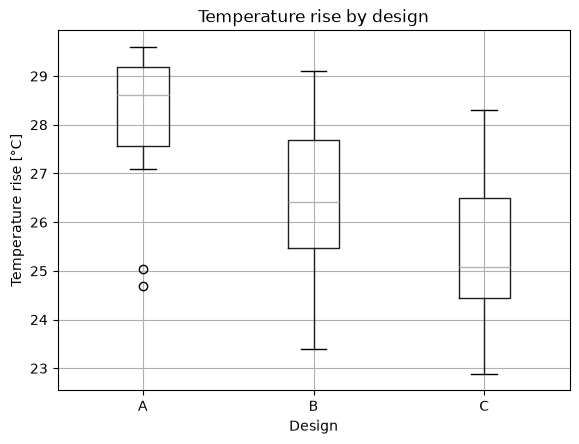

In [2]:
cooling = pd.read_csv("./data/heat_sink_designs.csv")
display(cooling.head())
print(f"Assemblies: {len(cooling)}")
print(f"Unique IDs: {cooling['assembly_id'].nunique()}")

# Your code here

# Build cooling_summary using groupby("design")["temp_rise_c"].agg(...).
cooling_summary = cooling.groupby("design")["temp_rise_c"].agg(n="size", mean = "mean", sd = "std")

# Display the summary and largest/smallest SD ratio.
display(cooling_summary)
largest_smallest_ratio = cooling_summary["sd"].max()/cooling_summary["sd"].min()
print("Ratio of largest to smallest STD:",round(largest_smallest_ratio,4))

# Make a boxplot; label temperature rise in degrees Celsius.
ax = cooling.boxplot(column = "temp_rise_c",by="design")
plt.suptitle("")
ax.set_title("Temperature rise by design")
ax.set_xlabel("Design")
ax.set_ylabel("Temperature rise [°C]")
plt.show()

### B. Build the ANOVA from squared deviations (2 pts)

Let $k$ be the number of designs and $N$ the total number of assemblies. Using the **individual measurements** and unrounded group means:

1. Calculate the grand mean $\bar y$ and all three sums of squares:

$$\mathrm{SSG}=\sum_j n_j(\bar y_j-\bar y)^2,\qquad
\mathrm{SSE}=\sum_j\sum_i(y_{ij}-\bar y_j)^2,\qquad
\mathrm{SST}=\sum_j\sum_i(y_{ij}-\bar y)^2.$$

   Check that $\mathrm{SST}\approx\mathrm{SSG}+\mathrm{SSE}$. The two sides may differ slightly because of floating-point arithmetic.
2. Calculate $df_G=k-1$, $df_E=N-k$, $\mathrm{MSG}=\mathrm{SSG}/df_G$, $\mathrm{MSE}=\mathrm{SSE}/df_E$, and $F=\mathrm{MSG}/\mathrm{MSE}$.
3. Find the **right-tail** $P$-value using `stats.f.sf(F, df_G, df_E)`. Display an ANOVA table with **Groups**, **Error**, and **Total** rows and columns for `df`, `sum_sq`, `mean_sq`, `F`, and `p_value`. Leave entries that do not apply blank or `NaN`.
4. Check your $F$ and $P$ against `stats.f_oneway(group_A, group_B, group_C)`, where each argument contains one design's individual measurements.

Keep `MSE`, `df_E`, and `cooling_summary` for Problem 3. Report sums of squares, mean squares, and $F$ to three decimals and $P$ to six decimals.

In [3]:
# Calculate the grand mean and the group means from cooling.
# Hint: groupby("design")["temp_rise_c"].transform("mean")
# returns the appropriate group mean for every row.

# Calculate SSG, SSE, SST, degrees of freedom, MSG, MSE, F, and P.
# Display the ANOVA table and check SST = SSG + SSE.
# Select the three groups and check with stats.f_oneway(...).

# Your code here
matched_means = cooling.groupby("design")["temp_rise_c"].transform("mean")
grand_mean = cooling["temp_rise_c"].mean()
cooling_SSG = (cooling_summary["n"]*(cooling_summary["mean"]-grand_mean)**2).sum()
cooling_SSE = ((cooling["temp_rise_c"]-matched_means)**2).sum() 
cooling_SST = ((cooling["temp_rise_c"]-grand_mean)**2).sum() 

print("SST vs SSG + SSE:",
      cooling_SST,"=", cooling_SSG + cooling_SSE,"? -->",
      np.isclose(cooling_SST,cooling_SSG + cooling_SSE))

k = len(cooling_summary.index)
cooling_N = cooling_summary["n"].sum()
df_G = k - 1
df_E = cooling_N - k
cooling_MSG = cooling_SSG/df_G
MSE = cooling_SSE/df_E
cooling_F = cooling_MSG/MSE
p_val = stats.f.sf(cooling_F, df_G, df_E)

table_ANOVA = pd.DataFrame({
    "df": [df_G, df_E, (cooling_N-1)],
    "sum_sq":[cooling_SSG, cooling_SSE, cooling_SST],
    "mean_sq":[cooling_MSG, MSE, np.nan],
    "F":[cooling_F, np.nan,np.nan],
    "p_value":[p_val, np.nan,np.nan]
},index=["Groups","Error","Total"])

verification_model = stats.f_oneway(
    cooling["temp_rise_c"].loc[cooling["design"]=="A"],
    cooling["temp_rise_c"].loc[cooling["design"]=="B"],
    cooling["temp_rise_c"].loc[cooling["design"]=="C"])

verification_F = np.isclose(cooling_F, verification_model.statistic)
verification_pval = np.isclose(p_val, verification_model.pvalue)

print("F and p-value match stats.f_oneway?:", verification_F, "and", verification_pval)

fmt = {col: "{:.3f}" for col in table_ANOVA.columns}          # every listed column gets 3 decimals
fmt["p_value"] = "{:.6f}" 
display(table_ANOVA.style.format(fmt))


SST vs SSG + SSE: 133.54983055555556 = 133.54983055555556 ? --> True
F and p-value match stats.f_oneway?: True and True


,df,sum_sq,mean_sq,F,p_value
Groups,2.000,37.993,18.997,6.560,0.003992
Error,33.000,95.556,2.896,nan,nan
Total,35.000,133.550,nan,nan,nan


### C. Explain the ANOVA (1 pt)

Answer in about **3–4 sentences**:

1. State $H_0$ and $H_A$ in terms of the population means and give the conclusion at $\alpha=0.05$, assuming the ANOVA conditions hold. Does rejection establish that **every pair** of population means differs?
2. Explain the $P$-value as a probability under the null hypothesis and the assumed model.
3. What variance does MSE estimate? Explain why ANOVA compares **mean squares**, rather than treating SSG and SSE themselves as variance estimates.

**Answer:** 
1. $H_0$: $\mu_A = \mu_B = \mu_C$, $H_A$: At least one of the population means differs. Given that the p-value, 0.003992, < 0.05, we reject $H_0$ because we have convincing evidence that at least one of the population means differs; however, rejecting $H_0$ does not mean that every pair of population means differs--it just means **at least one** of the pairs of population means differs.
2. The p-value of 0.003992 represents a 0.3992% chance of obtaining a sample with at least as high of a ratio of between-group variability in temperature rise to within-group variability if the population means all truly match and all ANOVA conditions are met (observations are independendent, groups have approximatley normal distributions, and group variances are approximatley equal).
3. The MSE estimates the true population within-group variance of electronic assemblies' temperature rises (this variance is shared across all heat sink designs), and the reason why ANOVA compares the mean squares rather than the sums of squares is because it adjusts for group count and observation count (the SSG grows with higher group count and the SSE grows with higher observation count, which means that the F statsistic comparison would be dependent on study design rather than actual differences between the between-group and within-group variance estimates if we did not account for group and observation count).

## LE12-3. Follow-up comparisons and the unit of observation (3 pts)

### A. Which pairs have evidence of different means? (2 pts)

Investigate **all three pairs**: A–B, A–C, and B–C. Use the pooled error estimate from Problem 2, as in the lecture:

$$\mathrm{SE}_{ij}=\sqrt{\mathrm{MSE}\left(\frac{1}{n_i}+\frac{1}{n_j}\right)},\qquad
t_{ij}=\frac{\bar y_i-\bar y_j}{\mathrm{SE}_{ij}},\qquad df=df_E.$$

1. Build a table with each pair, its mean difference (first minus second), SE, $t$, and **two-sided** $P$-value. Use `2 * stats.t.sf(abs(t), df_E)` and the **same MSE and error degrees of freedom** for every pair.
2. Compute the number of comparisons $K=k(k-1)/2$ and the Bonferroni cutoff $\alpha_{\mathrm{each}}=0.05/K$. Add columns showing significance at the ordinary 0.05 cutoff and at the Bonferroni cutoff. Compare unrounded $P$-values.
3. In **3–4 sentences**, identify which pairs survive the adjustment, which decision changes, and which design has the lower sample mean for each surviving comparison. Explain why a nonsignificant pairwise result does not establish equal population means.

**Answer:** Pair (A,C) survived the Boneferroni cutoff, whereas pair (A,B) is no longer statistically singnificant after the cutoff. In the surviving pair, (A,C), design C has the lower sample mean. A nonsignficant pairwise result does not establish equal population means because there is still a possiblity that there is a very small difference in population means that was not picked up on due to our small sample size (n=12). 

In [4]:
pairs = [("A", "B"), ("A", "C"), ("B", "C")]

# Use cooling_summary, MSE, and df_E from Problem 2.
# Do not recompute a separate variance estimate for each pair.

# Your code here
# For each pair, calculate mean difference, pooled SE, t, and two-sided P.
pairs_set1 = [pair[0] for pair in pairs]
pairs_set2 = [pair[1] for pair in pairs]

paired_table = pd.DataFrame({
    "mean_difference": cooling_summary["mean"].loc[pairs_set1].to_numpy() - cooling_summary["mean"].loc[pairs_set2].to_numpy(),
    "SE":np.sqrt(MSE*((1/cooling_summary["n"].loc[pairs_set1].to_numpy())+(1/cooling_summary["n"].loc[pairs_set2].to_numpy()))),
},index=(pairs))

paired_table["t"] = paired_table["mean_difference"]/paired_table["SE"]
paired_table["two-sided p_value"] = 2 * stats.t.sf(abs(paired_table["t"]), df_E)

# Add the ordinary and Bonferroni significance decisions.
big_k = k*(k-1)/2
alpha_each = alpha/big_k
mask1 = paired_table["two-sided p_value"] < alpha
mask2 = paired_table["two-sided p_value"] < alpha_each

paired_table["decision at alpha"] = np.where(mask1, "Reject H0", "Fail to reject H0")
paired_table["decision at alpha_each"] = np.where(mask2, "Reject H0", "Fail to reject H0")

print("K =",big_k,",  alpha_each =",alpha_each)
 
display(paired_table.style.format({"two-sided p_value": "{:.6f}"}))

K = 3.0 ,  alpha_each = 0.016666666666666666


,mean_difference,SE,t,two-sided p_value,decision at alpha,decision at alpha_each
"('A', 'B')",1.498333,0.694700,2.156805,0.038402,Reject H0,Fail to reject H0
"('A', 'C')",2.500000,0.694700,3.598674,0.001034,Reject H0,Reject H0
"('B', 'C')",1.001667,0.694700,1.441869,0.158763,Fail to reject H0,Fail to reject H0


### B. Would repeated readings give the same information? (1 pt)

Consider a **different** experiment: the team builds only **one assembly per design**, then records its temperature 12 times. The resulting file still has 36 rows. A colleague proposes analyzing it as though there were 12 independent assemblies per design.

In **3–4 sentences**, identify the experimental units and the actual number of independently tested assemblies per design. Explain why repeated readings from the same assembly do not provide independent replication of the design, why the ANOVA error estimate and $P$-value from that proposed analysis would be questionable, and how you would redesign the experiment.

**Answer:** The experimental units in this changed experiment are the electronics assemblies, and each design only has one independently tested assembly. Repeated readings from the same assembly do not provide independent replication of the design because each individual reading is linked to the other readings by having the same electronics assembly (this is problematic because certain elecrtronics assemblies might naturally have a higher temperature rise, and we wouldnt be able to account for this variation when comparing the difference in mean temperature rise between heatsink designs since each design only has one electronics assembly assigned to it). This proposed analysis violates the independence condition for the ANOVA test, meaning the error estimate and p-value would be questionable as a result of the supposed within-group variation really being the variation of readings for individual electronics assemblies (this will likley result in less within-group variation and thus a greater F statsitic since the ratio of between-group to within-group variation will be higher), so a proper redesign of the experiment would look like the intial design: randomly assigning numerous electronics assemblies to every heatsink design, that way the independence condition is satisfied.

## Session records

At the end of each working session, type **"make my record"** in the chat and paste the block it produces into the cell below. If you work across several sessions, paste each new block underneath the previous one.

Session records are not graded for correctness or for how much help you needed, and extra credit is given for a record that shows you attempted the problem. They are read to find out which steps are hardest, and used to improve the course.

<!-- Paste your session record blocks in this cell, one after another. -->

*(session records go here)*
{
  "schema_version": "engr-tutor-export-2",
  "assignment": "WA12",
  "export_n": 1,
  "session_date": "2026-11-24",
  "messages": [
    {"i": 1, "who": "student", "text": "Do I include both the smaller and larger experiment for LE12 part A (when calculating the SE)?"},
    {"i": 2, "who": "tutor", "text": "Yes, both. The prompt asks for one results table with a row for each experiment. Arithmetic on the columns of experiments applies to every row at once, so each row gets its own SE from its own n and SD. [trimmed]"},
    {"i": 3, "who": "student", "text": "Is there a quick way to change the true and false in a mask to be reject H0 and fail to reject H0?"},
    {"i": 4, "who": "tutor", "text": "Explained np.where(condition, value_if_true, value_if_false) on an unrelated table, and .map on a Boolean column as an alternative; mentioned comparing against alpha. [trimmed]"},
    {"i": 5, "who": "student", "text": "Is the way my results are formatted acceptable, or do I need to make a separate table for results?\n\n```python\nimport numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\nfrom scipy import stats\n\npd.set_option(\"display.precision\", 4)\nalpha = 0.05\n\nexperiments = pd.DataFrame({\n    \"experiment\": [\"Smaller\", \"Larger\"],\n    \"n_standard\": [100, 1600],\n    \"n_new\": [100, 1600],\n    \"mean_standard\": [31.8, 31.8],\n    \"mean_new\": [31.3, 31.3],\n    \"sd_standard\": [4.0, 4.0],\n    \"sd_new\": [4.0, 4.0],\n})\n\n\n# Your code here\n# Calculate the saving, estimated SE, z, two-sided P, and interval.\nci_multiplier = 2\nalpha = 0.05\nexperiments[\"se_estimated\"] = np.sqrt((experiments[\"sd_standard\"]**2)/experiments[\"n_standard\"] + (experiments[\"sd_new\"]**2)/experiments[\"n_new\"])\nexperiments[\"mean_diff\"] = experiments[\"mean_standard\"] - experiments[\"mean_new\"]\nexperiments[\"z-score\"] = experiments[\"mean_diff\"] / experiments[\"se_estimated\"]\nexperiments[\"p-value\"] = 2*stats.norm.sf(abs(experiments[\"z-score\"]))\nexperiments[\"lower_bound_ci\"] = experiments[\"mean_diff\"] - ci_multiplier*experiments[\"se_estimated\"]\nexperiments[\"upper_bound_ci\"] = experiments[\"mean_diff\"] + ci_multiplier*experiments[\"se_estimated\"]\nmask = experiments[\"p-value\"] < alpha\nexperiments[\"decision_at_alpha\"] = np.where(mask, \"Reject H0\", \"Fail to reject H0\")\n\n# Display a labeled results table with both experiments.\ndisplay(experiments)\n\n```", "code": true},
    {"i": 6, "who": "tutor", "text": "Confirmed the calculations follow the printed formulas and that adding columns to experiments is acceptable. Flagged that the starter display.precision of 4 caps P-values at four decimals; described pd.option_context and .style.format as display-only options, noted the wide table and the duplicate alpha line. [trimmed]"},
    {"i": 7, "who": "student", "text": "Does option 2 need additional libraries?"},
    {"i": 8, "who": "tutor", "text": "Explained that .style is part of pandas but needs jinja2, how to install it with %pip, and how the format dictionary works; mentioned pd.option_context as an alternative. [trimmed]"},
    {"i": 9, "who": "student", "text": "Is there a way to write this properly and efficiently?\n\n```python\n\nresults_display_list = [\"mean_diff\",\"se_estimated\",\"z-score\",\"p-value\",\"lower_bound_ci\",\"upper_bound_ci\",\"decision_at_alpha\"]\n\n# Display a labeled results table with both experiments.\ndisplay(experiments[results_display_list])\nexperiments[results_display_list].style.format({\"mean_diff\",\"se_estimated\",\"z-score\",\"lower_bound_ci\",\"upper_bound_ci\",\"decision_at_alpha\": \"{:.3f}\", \"p-value\": \"{:.6f}\"})\n```", "code": true},
    {"i": 10, "who": "tutor", "text": "Explained the dictionary syntax problem and a dictionary comprehension on unrelated data; noted the text column should not be in the format dict, that two tables would display, and that the experiment column was missing from the list. [trimmed]"},
    {"i": 11, "who": "student", "text": "---------------------------------------------------------------------------\nAttributeError                            Traceback (most recent call last)\nCell In[20], line 39\n     35 # Display a labeled results table with both experiments.\n     36 ##display(experiments[results_display_list])\n     37 fmt = {col: \"{:.3f}\" for col in results_display_list}          # every listed column gets 3 decimals\n     38 fmt[\"pval\"] = \"{:.6f}\"\n---> 39 experiments[results_display_list].style.format(fmt)\n\nFile ~\\AppData\\Local\\Python\\pythoncore-3.14-64\\Lib\\site-packages\\pandas\\core\\generic.py:6194, in NDFrame.__getattr__(self, name)\n   6190             and name not in self._accessors\n   6191             and self._info_axis._can_hold_identifiers_and_holds_name(name)\n   6192         ):\n   6193             return self[name]\n-> 6194         return object.__getattribute__(self, name)\n\nFile ~\\AppData\\Local\\Python\\pythoncore-3.14-64\\Lib\\site-packages\\pandas\\core\\frame.py:1430, in DataFrame.style(self)\n   1426         \"\"\"\n   1427         # Raise AttributeError so that inspect works even if jinja2 is not installed.\n   1428         has_jinja2 = import_optional_dependency(\"jinja2\", errors=\"ignore\")\n   1429         if not has_jinja2:\n-> 1430             raise AttributeError(\"The '.style' accessor requires jinja2\")\n   1431 \n   1432         from pandas.io.formats.style import Styler\n   1433 \n\nAttributeError: The '.style' accessor requires jinja2", "code": true},
    {"i": 12, "who": "tutor", "text": "Explained the jinja2 error and %pip install jinja2 with a kernel restart; offered pd.option_context as an alternative; pointed out the text column in fmt and that fmt[\"pval\"] does not match the column \"p-value\". [trimmed]"},
    {"i": 13, "who": "student", "text": "```python\nimport numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\nfrom scipy import stats\n\npd.set_option(\"display.precision\", 4)\nalpha = 0.05\n\nexperiments = pd.DataFrame({\n    \"experiment\": [\"Smaller\", \"Larger\"],\n    \"n_standard\": [100, 1600],\n    \"n_new\": [100, 1600],\n    \"mean_standard\": [31.8, 31.8],\n    \"mean_new\": [31.3, 31.3],\n    \"sd_standard\": [4.0, 4.0],\n    \"sd_new\": [4.0, 4.0],\n})\n\n\n# Your code here\n# Calculate the saving, estimated SE, z, two-sided P, and interval.\nci_multiplier = 2\nalpha = 0.05\nexperiments[\"se_estimated\"] = np.sqrt((experiments[\"sd_standard\"]**2)/experiments[\"n_standard\"] + (experiments[\"sd_new\"]**2)/experiments[\"n_new\"])\nexperiments[\"mean_diff\"] = experiments[\"mean_standard\"] - experiments[\"mean_new\"]\nexperiments[\"z-score\"] = experiments[\"mean_diff\"] / experiments[\"se_estimated\"]\nexperiments[\"p-value\"] = 2*stats.norm.sf(abs(experiments[\"z-score\"]))\nexperiments[\"lower_bound_ci\"] = experiments[\"mean_diff\"] - ci_multiplier*experiments[\"se_estimated\"]\nexperiments[\"upper_bound_ci\"] = experiments[\"mean_diff\"] + ci_multiplier*experiments[\"se_estimated\"]\nmask = experiments[\"p-value\"] < alpha\nexperiments[\"decision_at_alpha\"] = np.where(mask, \"Reject H0\", \"Fail to reject H0\")\n\nresults_display_list = [\"mean_diff\",\"se_estimated\",\"z-score\",\"p-value\",\"lower_bound_ci\",\"upper_bound_ci\",\"decision_at_alpha\"]\n\n# Display a labeled results table with both experiments.\n##display(experiments[results_display_list])\nfmt = {col: \"{:.3f}\" for col in results_display_list}          # every listed column gets 3 decimals\nfmt[\"pval\"] = \"{:.6f}\" \nexperiments[results_display_list].style.format(fmt)\n```\n\n---------------------------------------------------------------------------\nValueError                                Traceback (most recent call last)\nFile ~\\AppData\\Local\\Python\\pythoncore-3.14-64\\Lib\\site-packages\\pandas\\io\\formats\\style.py:374, in Styler._repr_html_(self)\n    373 if get_option(\"styler.render.repr\") == \"html\":\n--> 374     return self.to_html()\n    375 return None\n...\n-> 1984     func_0 = lambda x: formatter.format(x)\n\nValueError: Unknown format code 'f' for object of type 'str'\nOutput is truncated. View as a scrollable element or open in a text editor. Adjust cell output settings...", "code": true},
    {"i": 14, "who": "tutor", "text": "Identified that \"{:.3f}\" was applied to the text column decision_at_alpha and that fmt[\"pval\"] does not match \"p-value\"; showed the pattern on unrelated data. [trimmed]"},
    {"i": 15, "who": "student", "text": "I got it working, thank you!"},
    {"i": 16, "who": "tutor", "text": "Acknowledged and mentioned LE12-1B as the next part, or stopping with a record. [trimmed]"},
    {"i": 17, "who": "student", "text": "```markdown\n**Answer:**\n1. The significance changes even though $\\widehat\\Delta$ (the observed time saving) does not because the $\\widehat{\\mathrm{SE}}(\\widehat\\Delta)$ for the larger experiment is much smaller as a result of a greater $n$ (while $s$ is equal across both experiments), which results in a higher z-score and lower p-value. Even though the higher p-value of the smaller experiment results in the significance decision of failing to reject $H_0$, it does not establish that the true saving is zero, as there is a chance a Type II error occured (failing to reject $H_0$ when $H_0$ is false).\n2. The 95% confidence interval for the larger experiment's estimated time saving is [0.217,0.783] seconds, which does not contain 2 seconds, the time saving value needed to justifiy the cost of the fixture. The larger experiment's small, statitically significant p-value alone does not justifiy buying the fixture because it only provides evidence that there is a time saving and does not quantifiy said time saving (a lack of quantification prevents us from being able to tell if there is evidence that the difference is larger than 2 seconds).\n3. Switiching to a one-sided test after seeing the results is bad statisitical practice, deviates from the planned analysis, and halves the p-value; however, a greater p-value in this case does not quantifiy the time saving (as mentioned in 2.), it gives the probabilty of obtaining a time saving as or more extreme as those obtained under $H-0$ (time saving = 0).\n```"},
    {"i": 18, "who": "tutor", "text": "Gave feedback question by question without writing answers: asked what the smaller experiment's interval still allows, where the whole larger interval sits relative to 2, the effect of a post-hoc one-sided switch on false alarms, and the link between the P-value definition and H0; noted length, spelling, and H_0 notation. [trimmed]"},
    {"i": 19, "who": "student", "text": "I have revised 1 and 2, please let me know if there is any major inaccuracy or any missing points\n\n```markdown\n1. The significance changes even though $\\widehat\\Delta$ (the observed time saving) does not because the $\\widehat{\\mathrm{SE}}(\\widehat\\Delta)$ for the larger experiment is much smaller as a result of a greater $n$ (while $s$ is equal across both experiments), which results in a higher z-score and lower p-value. Even though the higher p-value of the smaller experiment results in the significance decision of failing to reject $H_0$, it does not establish that the true saving is zero, as there is a chance a Type II error occured (failing to reject $H_0$ when $H_0$ is false).\n2. The 95% confidence interval for the larger experiment's estimated time saving is [0.217,0.783] seconds, which does not contain or exceed 2 seconds, the time saving value needed to justifiy the cost of the fixture. The larger experiment's small, statistically significant p-value alone does not justifiy buying the fixture because it only provides evidence that there is a time saving and does not quantifiy said time saving (a lack of quantification prevents us from being able to tell if there is evidence that the difference is larger than 2 seconds).\n```"},
    {"i": 20, "who": "tutor", "text": "Said there was no major inaccuracy and the interval matched a reference calculation; pointed again to the smaller experiment's interval versus zero, the position of the whole larger interval relative to 2, the contrast between the questions a P-value and the requirement answer, plus spelling, wording, and length. [trimmed]"},
    {"i": 21, "who": "student", "text": "All I can think of for #3 is that changing the test to a one sided test doubles the p-value and may result in more false alarms\n\n```markdown\n3. Switiching to a one-sided test after seeing the results is bad statisitical practice, deviates from the planned analysis, and doubles the p-value; however, a greater p-value in this case does not quantifiy the time saving (as mentioned in 2.), it gives the probabilty of obtaining a time saving as or more extreme as those obtained under $H_0$ (time saving = 0).\n```"},
    {"i": 22, "who": "tutor", "text": "Asked which direction the one-sided P moves versus the two-sided; explained on a coin example why choosing the tail after seeing data inflates the false-alarm rate, and that the P-value is computed assuming H0, so it is not the probability that H0 is true. [trimmed]"},
    {"i": 23, "who": "student", "text": "It halves the p-value, I miscorrected myself"},
    {"i": 24, "who": "tutor", "text": "Confirmed halving is correct and explained why that makes the switch tempting; asked the student to address the false-alarm effect and the P-value assumption in the revision. [trimmed]"},
    {"i": 25, "who": "student", "text": "```markdown\nSwitiching to a one-sided test after seeing the results is bad statisitical practice, deviates from the planned analysis, halves the p-value, and doubles the chance of false alarms (Type I errors); however, a greater p-value in this case does not quantifiy the time saving (as mentioned in 2.), it gives the probabilty of obtaining a time saving as or more extreme as those obtained under $H_0$ (assuming that time saving = 0).\n```"},
    {"i": 26, "who": "tutor", "text": "Noted progress; said the P-value half still did not state why it is not the probability of H0, and that the leftover Q2 clause, length, and spelling needed attention; reminded of the open Q1 and Q2 points. [trimmed]"},
    {"i": 27, "who": "student", "text": "```markdown\n3. Switiching to a one-sided test after seeing the results is bad statisitical practice, deviates from the planned analysis, halves the p-value, and doubles the chance of false alarms (Type I errors); however, a smaller p-value in this case does not quantifiy the time saving (as mentioned in 2.) or give the chance of $H_0$ being true, it gives the probabilty of obtaining a time saving as or more extreme as those obtained under $H_0$ (assuming that time saving = 0).\n```"},
    {"i": 28, "who": "tutor", "text": "Noted the fix to 'smaller' and the added claim; said the 'why' was still implied, the Q2 clause remained, the first half was a list of labels, and the answer was too long; reminded of the open Q1 and Q2 points. [trimmed]"}
  ],
  "events": [
    {"i": 3, "part": "12-1A", "type": "explain"},
    {"i": 5, "part": "12-1A", "type": "code"},
    {"i": 7, "part": "12-1A", "type": "explain"},
    {"i": 9, "part": "12-1A", "type": "code"},
    {"i": 11, "part": "12-1A", "type": "code"},
    {"i": 13, "part": "12-1A", "type": "code"},
    {"i": 15, "part": "12-1A", "type": "part_pass"}
  ],
  "parts": [
    {"part": "12-1A", "exchanges": 8, "max_tier": 3, "passed": true},
    {"part": "12-1B", "exchanges": 6, "max_tier": 3, "passed": false}
  ],
  "tutor_assessment": [
    "The student stalled longest on 12-1B. The obstacles were using the smaller experiment's interval (compared with zero) to explain why failing to reject does not show a zero saving, saying where the whole larger interval sits relative to 2 seconds, and explaining why a post-hoc one-sided switch inflates false alarms and why a P-value assumes H0 rather than measuring its probability. On 12-1A the main obstacles were the six-decimal display, the Styler format dictionary, and a missing jinja2 install.",
    "No unstuck or release-valve use occurred in this session, so nothing looks like a tutoring failure there. The student worked through the 12-1A display errors with targeted hints, and the 12-1B revisions were still in progress when the session ended."
  ]
}
{
  "schema_version": "engr-tutor-export-2",
  "assignment": "WA12",
  "export_n": 2,
  "session_date": "2026-11-24",
  "messages": [
    {"i": 1, "who": "student", "text": "```python\ncooling = pd.read_csv(\"./data/heat_sink_designs.csv\")\ndisplay(cooling.head())\nprint(f\"Assemblies: {len(cooling)}\")\nprint(f\"Unique IDs: {cooling['assembly_id'].nunique()}\")\n\n# Your code here\n\n# Build cooling_summary using groupby(\"design\")[\"temp_rise_c\"].agg(...).\ncooling_summary = cooling.groupby(\"design\")[\"temp_rise_c\"].agg(n=\"size\", mean = \"mean\", sd = \"std\")\n\n# Display the summary and largest/smallest SD ratio.\ndisplay(cooling_summary)\nlargest_smallest_ratio = cooling_summary[\"sd\"].max()/cooling_summary[\"sd\"].min()\nprint(\"Ratio of largest to smallest STD:\",round(largest_smallest_ratio,4))\n\n# Make a boxplot; label temperature rise in degrees Celsius.\nax = cooling.boxplot(column = \"temp_rise_c\",by=\"design\")\nplt.suptitle(\"\")\nax.set_title(\"Temperature rise by design\")\nax.set_xlabel(\"Design\")\nax.set_ylabel(\"Temperature rise [°C]\")\nplt.show()\n```", "code": true},
    {"i": 2, "who": "tutor", "text": "Confirmed the cell follows the prompt (summary stored as cooling_summary, ratio, boxplot with labeled axis and units); noted keeping cooling_summary unrounded for LE12-3A and running the LE12-1 cell first; listed questions to think through for the 2-3 sentences without writing them. [trimmed]"},
    {"i": 3, "who": "student", "text": "What is meant by explaining why the small samples cant establish normality? Is it that they are insufficient to create a normalized sample distribution or show that their respective distribution is approximately normal?"},
    {"i": 4, "who": "tutor", "text": "Explained that the normality condition concerns the populations, not the sample's own shape; small samples are noisy about shape and a reasonable-looking plot is absence of evidence, not evidence, illustrated with unrelated quiz scores. [trimmed]"},
    {"i": 5, "who": "student", "text": "```markdown\n**Answer:** The spreads of design B and C appear simmilar, with both boxplots having simmilar ranges and IQRs; however, design A has two outliers, shows signs of skewdness, and has a much smaller range outside of its two outliers. These small samples are insufficient to establish normality because there is a chance that the sample includes extreme values due to random variation that result in a skewed/non-normal sample distribution. Independence must be justified in order to be able to run an ANOVA test and determine if any heat sink designs deviate from the others in terms of how they cool.\n```"},
    {"i": 6, "who": "tutor", "text": "Gave question-style feedback on each part: use the SD ratio for spreads, say what flagged points mean, cover both directions for normality and keep sample and population distinct, and say why independence comes from the design; noted spelling. [trimmed]"},
    {"i": 7, "who": "student", "text": "```markdown\n**Answer:** Design A has two outliers, shows signs of skewdness, and has a much smaller range than design A and B outside of its two outliers; however, all three study designs have very close standard deviations, with the ratio of largest to smallest standard deviation being around 1.06. These small samples are insufficient to establish normality because there is a chance that a sample distrbution from a normal population can appear non-normal (and vice-versa: a normal sample distribution from a heavily skewed population distribution) due to random variation. Independence is gaurenteed to be justified based on the study design because the 36 electronic assemblies are independently prepared and randomly assigned to designs A, B, and C.\n```"},
    {"i": 8, "who": "tutor", "text": "Noted the normality sentence now covers both directions; pointed out the 'A and B' slip, the tension between the range claim and the close SDs, the missing 'so what' for the outliers, the overstated 'guaranteed', and spelling. [trimmed]"},
    {"i": 9, "who": "student", "text": "Design A has two outliers and shows signs of skewdness compared to designs B and C; however, all three study designs have very close standard deviations, with the ratio of largest to smallest standard deviation being around 1.06."},
    {"i": 10, "who": "tutor", "text": "Said the slip was fixed and the ratio matched a reference calculation; asked what the student concludes from the outliers and skew together with the close SDs, what to do with flagged points, and whether the figure supports 'skewness'. [trimmed]"},
    {"i": 11, "who": "student", "text": "Independence is justified based on the study design because the 36 electronic assemblies are independently prepared and randomly assigned to designs A, B, and C."},
    {"i": 12, "who": "tutor", "text": "Noted the wording improved; asked why independence must come from the design rather than the data, and whether the description says how many times each assembly was tested; reminded the student that the outlier clause was still open and the pieces needed joining and tightening. [trimmed]"},
    {"i": 13, "who": "student", "text": "Is there an easy way to go through each design group and subtract the individual temp rise from its design's mean?"},
    {"i": 14, "who": "tutor", "text": "Explained groupby transform(\"mean\") returning one group mean per row, with an unrelated plant-height example, and why subtracting a plain groupby mean misaligns the indexes and gives a sum of 0. [trimmed]"},
    {"i": 15, "who": "student", "text": "Understood, thank you"},
    {"i": 16, "who": "tutor", "text": "Invited the student to build the group means and deviations in the LE12-2B cell; reminded them the LE12-2A sentences were still in progress. [trimmed]"},
    {"i": 17, "who": "student", "text": "What is the numpy command for comparing two floats for equality?"},
    {"i": 18, "who": "tutor", "text": "Explained np.isclose versus == for floats, default tolerances, np.allclose for arrays, and its use for the SST check. [trimmed]"},
    {"i": 19, "who": "student", "text": "Can you explain and illustrate what should be included in the ANOVA table?\nThis is where I am at:\n\n```python\n# Calculate the grand mean and the group means from cooling.\n# Hint: groupby(\"design\")[\"temp_rise_c\"].transform(\"mean\")\n# returns the appropriate group mean for every row.\n\n# Calculate SSG, SSE, SST, degrees of freedom, MSG, MSE, F, and P.\n# Display the ANOVA table and check SST = SSG + SSE.\n# Select the three groups and check with stats.f_oneway(...).\n\n# Your code here\nmatched_means = cooling.groupby(\"design\")[\"temp_rise_c\"].transform(\"mean\")\ngrand_mean = cooling[\"temp_rise_c\"].mean()\ncooling_SSG = (cooling_summary[\"n\"]*(cooling_summary[\"mean\"]-grand_mean)**2).sum()\ncooling_SSE = ((cooling[\"temp_rise_c\"]-matched_means)**2).sum() \ncooling_SST = ((cooling[\"temp_rise_c\"]-grand_mean)**2).sum() \n\nprint(\"SST vs SSG + SSE:\",\n      cooling_SST,\"=\", cooling_SSG + cooling_SSE,\"? -->\",\n      np.isclose(cooling_SST,cooling_SSG + cooling_SSE))\n\nk = len(cooling.columns)\ncooling_N = cooling_summary[\"n\"].sum()\ndf_G = k - 1\ndf_E = cooling_N - k\ncooling_MSG = cooling_SSG/df_G\ncooling_MSE = cooling_SSE/df_E\ncooling_F = cooling_MSG/cooling_MSE\np_val = stats.f.sf(cooling_F, df_G, df_E)\n```", "code": true},
    {"i": 20, "who": "tutor", "text": "Explained the layout of an ANOVA table (which cells are filled in the Groups, Error, and Total rows, NaN elsewhere) with a table built on invented fertilizer data; flagged k = len(cooling.columns) as counting columns rather than designs and the missing MSE name needed by LE12-3A. [trimmed]"},
    {"i": 21, "who": "student", "text": "Do I have everything now? \n\n```python\n# Calculate the grand mean and the group means from cooling.\n# Hint: groupby(\"design\")[\"temp_rise_c\"].transform(\"mean\")\n# returns the appropriate group mean for every row.\n\n# Calculate SSG, SSE, SST, degrees of freedom, MSG, MSE, F, and P.\n# Display the ANOVA table and check SST = SSG + SSE.\n# Select the three groups and check with stats.f_oneway(...).\n\n# Your code here\nmatched_means = cooling.groupby(\"design\")[\"temp_rise_c\"].transform(\"mean\")\ngrand_mean = cooling[\"temp_rise_c\"].mean()\ncooling_SSG = (cooling_summary[\"n\"]*(cooling_summary[\"mean\"]-grand_mean)**2).sum()\ncooling_SSE = ((cooling[\"temp_rise_c\"]-matched_means)**2).sum() \ncooling_SST = ((cooling[\"temp_rise_c\"]-grand_mean)**2).sum() \n\nprint(\"SST vs SSG + SSE:\",\n      cooling_SST,\"=\", cooling_SSG + cooling_SSE,\"? -->\",\n      np.isclose(cooling_SST,cooling_SSG + cooling_SSE))\n\nk = len(cooling.columns)\ncooling_N = cooling_summary[\"n\"].sum()\ndf_G = k - 1\ndf_E = cooling_N - k\ncooling_MSG = cooling_SSG/df_G\ncooling_MSE = cooling_SSE/df_E\ncooling_F = cooling_MSG/cooling_MSE\np_val = stats.f.sf(cooling_F, df_G, df_E)\n\ntable_ANOVA = pd.DataFrame({\n    \"df\": [df_G, df_E, (cooling_N-1)],\n    \"sum_sq\":[cooling_SSG, cooling_SSE, cooling_SST],\n    \"mean_sq\":[cooling_MSG, cooling_MSE, np.nan],\n    \"F\":[cooling_F, np.nan,np.nan],\n    \"p-value\":[p_val, np.nan,np.nan]\n},index=[\"Groups\",\"Error\",\"Total\"])\n\nverification_model = stats.f_oneway(\n    cooling[\"temp_rise_c\"].loc[cooling[\"design\"]==\"A\"],\n    cooling[\"temp_rise_c\"].loc[cooling[\"design\"]==\"B\"],\n    cooling[\"temp_rise_c\"].loc[cooling[\"design\"]==\"C\"])\n\nverification_F = np.isclose(cooling_F, verification_model.statistic)\nverification_pval = np.isclose(p_val, verification_model.pvalue)\n\nprint(\"F and p-value match stats.f_oneway?:\", verification_F, \"and\", verification_pval)\n\ndisplay(table_ANOVA)\n```", "code": true},
    {"i": 22, "who": "tutor", "text": "Confirmed the table structure, f_oneway check, and group selection were correct; listed what remained: a name MSE for LE12-3A, k still counting columns, column named p-value instead of p_value, and the three-decimal/six-decimal display with .style.format and na_rep; suggested showing the f_oneway numbers as well as True/False. [trimmed]"}
  ],
  "events": [
    {"i": 1, "part": "12-2A", "type": "code"},
    {"i": 3, "part": "12-2A", "type": "explain"},
    {"i": 13, "part": "12-2B", "type": "explain"},
    {"i": 17, "part": "12-2B", "type": "explain"},
    {"i": 19, "part": "12-2B", "type": "explain"},
    {"i": 19, "part": "12-2B", "type": "code"},
    {"i": 21, "part": "12-2B", "type": "code"}
  ],
  "parts": [
    {"part": "12-2A", "exchanges": 6, "max_tier": 3, "passed": false},
    {"part": "12-2B", "exchanges": 4, "max_tier": 3, "passed": false}
  ],
  "tutor_assessment": [
    "The student stalled longest on the 12-2A sentences. The obstacles were using the SD ratio and boxes together to judge spread, saying what to do with the flagged points in A, and explaining why independence must be argued from the study design rather than read from the data. In 12-2B the code was nearly complete; the open items were counting designs for k instead of columns, giving the mean square the name MSE for LE12-3A, matching the p_value column name, and the six-decimal display.",
    "No unstuck or release-valve use occurred in this session, so nothing looks like a tutoring failure there. Both 12-2A and 12-2B were still in progress when the session ended, so neither is marked as passed."
  ]
}
{
  "schema_version": "engr-tutor-export-2",
  "assignment": "WA12",
  "export_n": 3,
  "session_date": "2026-11-25",
  "messages": [
    {"i": 1, "who": "student", "text": "```markdown\n1. $H_0$: $\\mu_A = \\mu_B = \\mu_C$, $H_A$: At least one of the population means differs. Given that the p-value, 0.003992, < 0.05, we reject $H_0$ because we have convincing evidence that at least one of the population means differs; however, rejecting $H_0$ does not mean that every pair of population means differs--it just means **at least one** of the pairs of population means differs.\n2. The p-value of 0.003992 represents a 0.3992% chance of obtaining as high of a between-group variability in temperature rise compared to the within-group variability for each heat sink design.\n3. The MSE estimates the within-group variance, and ANOVA compares the mean squares rather than the sums of squares because the mean squares account for the degrees of freedom for the groups and the errors, $df_G$ and $df_E$, respectivley.\n```"},
    {"i": 2, "who": "tutor", "text": "Said Q1 was in good shape and to copy the P-value from the displayed table; asked what the P-value is the probability of and what it is computed assuming (null and model); asked why raw sums are not comparable and which population quantity MSE estimates; noted length and spelling. [trimmed]"},
    {"i": 3, "who": "student", "text": "```markdown\n2. The p-value of 0.003992 represents a 0.3992% chance of obtaining a sample with as high of a between-group variability in temperature rise compared to the within-group variability for each heat sink design if the population means all truly match.\n```"},
    {"i": 4, "who": "tutor", "text": "Noted the improvement (condition stated, not a probability of H0); asked which single statistic combines the two variabilities, whether wording covers 'at least as large', that the model conditions were missing, and that 'for each heat sink design' was ambiguous. [trimmed]"},
    {"i": 5, "who": "student", "text": "The p-value of 0.003992 represents a 0.3992% chance of obtaining a sample with as high of a ratio of between-group variability in temperature rise to within-group variability for each heat sink design if the population means all truly match and all ANOVA conditions are met."},
    {"i": 6, "who": "tutor", "text": "Said the ratio and the model were now covered; asked about 'as high as' versus 'at least as large as', the ambiguous 'for each heat sink design', and spelling out the conditions. [trimmed]"},
    {"i": 7, "who": "student", "text": "The p-value of 0.003992 represents a 0.3992% chance of obtaining a sample with at least as high of a ratio of between-group variability in temperature rise to within-group variability if the population means all truly match and all ANOVA conditions are met (observations are independendent, groups have approximatley normal distributions, and group variances are approximatley equal)."},
    {"i": 8, "who": "tutor", "text": "Said this version works; noted optional naming of the F statistic, that the conditions concern populations, spelling, matching the table, and length; reopened Q3 with questions about the common variance and degrees of freedom. [trimmed]"},
    {"i": 9, "who": "student", "text": "The MSE estimates the within-group (within the same heat sink design) variance of electronic assemblies' temperature rises, and the reason why ANOVA compares the mean squares rather than the sums of squares is because it adjusts for the number of groups and observations."},
    {"i": 10, "who": "tutor", "text": "Said the first half was close and the second had the right instinct; asked whether MSE targets one shared variance or three, what the df values count, and what dividing a sum of squares by its df produces; noted length. [trimmed]"},
    {"i": 11, "who": "student", "text": "The MSE estimates the within-group variance of electronic assemblies' temperature rises across all heat sink designs, and the reason why ANOVA compares the mean squares rather than the sums of squares is because it adjusts for the number of groups and observations (the SSG grows with higher group count and the SSE grows with higher observation count, meaning that the F statistic could be manipuated if we didnt account for these changes)."},
    {"i": 12, "who": "tutor", "text": "Said the parenthetical now gives the core idea that sums grow with the number of terms; asked whether MSE targets one shared variance, whether 'group count' and 'observation count' match what df counts, what the real problem is beyond 'manipulation', and what division turns each sum into; noted length and spelling. [trimmed]"}
  ],
  "events": [],
  "parts": [
    {"part": "12-2C", "exchanges": 6, "max_tier": 3, "passed": false}
  ],
  "tutor_assessment": [
    "The student stalled longest on the third question of 12-2C. The obstacles were saying that MSE estimates a single common population variance shared by the designs, and explaining why sums of squares are divided by degrees of freedom so that mean squares serve as variance estimates and can be compared. The P-value sentence in Q2 also took several revisions before it covered the right tail and the model.",
    "No unstuck or release-valve use occurred in this session, so nothing looks like a tutoring failure there. The 12-2C answer was still being revised when the session ended, so it is not marked as passed."
  ]
}
{
  "schema_version": "engr-tutor-export-2",
  "assignment": "WA12",
  "export_n": 4,
  "session_date": "2026-11-25",
  "messages": [
    {"i": 1, "who": "student", "text": "Is this a more accurate explanation? The MSE estimates the true population within-group variance of electronic assemblies' temperature rises across all heat sink designs (which under $H_0$ are equal)"},
    {"i": 2, "who": "tutor", "text": "Said 'true population' was an improvement; asked what 'which' refers to, whether the equal-variance statement depends on H0 or belongs to the model assumptions, and whether MSE targets one shared variance; noted the sentence was incomplete and the length limit. [trimmed]"},
    {"i": 3, "who": "student", "text": "The MSE addresses the within-group variation, so is this saying that the MSE is trying to estimate the true-within group variation across all groups, since under H0, the variation is the same for all groups? In practice, is it calculating the average of the within-group variation for each group and then using that as an estimate for the true population variation?"},
    {"i": 4, "who": "tutor", "text": "Explained that H0 is about means while the common variance is a model assumption, that MSE is built from deviations about each group's own mean, and that MSE is a df-weighted pooled estimate of one common variance (equal to the plain average of group variances when group sizes match). [trimmed]"},
    {"i": 5, "who": "student", "text": "The MSE estimates the true population within-group variance of electronic assemblies' temperature rises (this is shared across all heat sink designs), and the reason why ANOVA compares the mean squares rather than the sums of squares is because it adjusts for group count, observation count, and degrees of freedom (the SSG grows with higher group count and the SSE grows with higher observation count, meaning that the F statsitic could be manipuated if we didnt account for these changes)."},
    {"i": 6, "who": "tutor", "text": "Said the first half now names a single shared quantity attributed to the model; asked whether group count and observation count are what df counts, what the real problem is beyond 'manipulation', and what dividing by df produces; noted length and spelling. [trimmed]"},
    {"i": 7, "who": "student", "text": "Is this more accurate: the SSG grows with higher group count and the SSE grows with higher observation count, meaning that the F statsistic comparison would be dependent on study design rather than actual differences between the between-group and within-group variances"},
    {"i": 8, "who": "tutor", "text": "Said this moved to the real issue; asked whether df counting independent pieces replaces the two counts, and what SSG/df_G and SSE/df_E each become and estimate; noted length and spelling. [trimmed]"},
    {"i": 9, "who": "student", "text": "Ill move onto LE3"},
    {"i": 10, "who": "tutor", "text": "Accepted moving on; served a12_le12_3; noted that MSE must be named for LE12-3A and k fixed; asked which numbers give the A-B difference and go into its SE and df. [trimmed]"},
    {"i": 11, "who": "student", "text": "Is there a way to extract the first number in each set of the pairs list? `pairs = [(\"A\", \"B\"), (\"A\", \"C\"), (\"B\", \"C\")]`"},
    {"i": 12, "who": "tutor", "text": "Explained tuple unpacking in a for loop, indexing a tuple, and a list comprehension, and how .loc takes the row label first. [trimmed]"},
    {"i": 13, "who": "student", "text": "Is there a way to work around this code error? I am trying to make it so that the code auto-updates with pairs to follow good coding practice.\n\n```python\npairs = [(\"A\", \"B\"), (\"A\", \"C\"), (\"B\", \"C\")]\n\n# Your code here\npairs_set1 = [pair[0] for pair in pairs]\npairs_set2 = [pair[1] for pair in pairs]\n\npaired_table = pd.DataFrame({\n    \"mean_difference\": cooling_summary[\"mean\"].loc[pairs_set1] - cooling_summary[\"mean\"].loc[pairs_set2],\n},index=(pairs))\n```\n\nValueError: cannot reindex on an axis with duplicate labels", "code": true},
    {"i": 14, "who": "tutor", "text": "Explained that Series subtraction aligns on index labels and duplicates fail; showed .to_numpy() and reset_index(drop=True) on unrelated data; noted the tuple index, the MSE name, and computing K from len(pairs). [trimmed]"},
    {"i": 15, "who": "student", "text": "How can I adjust the display precision of a single column in a display table?"},
    {"i": 16, "who": "tutor", "text": "Explained .style.format with a dictionary, na_rep, exact key matching, the Styler being display-only, and map or pd.option_context as alternatives. [trimmed]"},
    {"i": 17, "who": "student", "text": "Am I missing anything? \n\n```python\npairs = [(\"A\", \"B\"), (\"A\", \"C\"), (\"B\", \"C\")]\n\npairs_set1 = [pair[0] for pair in pairs]\npairs_set2 = [pair[1] for pair in pairs]\n\npaired_table = pd.DataFrame({\n    \"mean_difference\": cooling_summary[\"mean\"].loc[pairs_set1].to_numpy() - cooling_summary[\"mean\"].loc[pairs_set2].to_numpy(),\n    \"SE\":np.sqrt(MSE*((1/cooling_summary[\"n\"].loc[pairs_set1].to_numpy())+(1/cooling_summary[\"n\"].loc[pairs_set2].to_numpy()))),\n},index=(pairs))\n\npaired_table[\"t\"] = paired_table[\"mean_difference\"]/paired_table[\"SE\"]\npaired_table[\"two-sided p_value\"] = 2 * stats.t.sf(abs(paired_table[\"t\"]), df_E)\n\nbig_k = k*(k-1)/2\nalpha_each = alpha/big_k\nmask1 = paired_table[\"two-sided p_value\"] < alpha\nmask2 = paired_table[\"two-sided p_value\"] < alpha_each\n\npaired_table[\"decision at alpha\"] = np.where(mask1, \"Reject H0\", \"Fail to reject H0\")\npaired_table[\"decision at alpha_each\"] = np.where(mask2, \"Reject H0\", \"Fail to reject H0\")\n\nprint(\"alpha_each =\",alpha_each)\n \ndisplay(paired_table.style.format({\"two-sided p_value\": \"{:.6f}\"}))\n```", "code": true},
    {"i": 18, "who": "tutor", "text": "Confirmed the table follows the prompt; flagged that k still counted columns, that K was not printed, and optional index labels; listed questions for the 3-4 sentences without writing them. [trimmed]"},
    {"i": 19, "who": "student", "text": "Would this fix the k calculation? `k = len(cooling_summary.index)`"},
    {"i": 20, "who": "tutor", "text": "Confirmed it counts the designs; said to rerun LE12-2B before LE12-3A and noted the MSE name and p_value column name and display format still open in LE12-2B. [trimmed]"}
  ],
  "events": [
    {"i": 1, "part": "12-2C", "type": "explain"},
    {"i": 3, "part": "12-2C", "type": "explain"},
    {"i": 11, "part": "12-3A", "type": "explain"},
    {"i": 13, "part": "12-3A", "type": "code"},
    {"i": 15, "part": "12-3A", "type": "explain"},
    {"i": 17, "part": "12-3A", "type": "code"}
  ],
  "parts": [
    {"part": "12-2C", "exchanges": 4, "max_tier": 3, "passed": false},
    {"part": "12-3A", "exchanges": 5, "max_tier": 3, "passed": false}
  ],
  "tutor_assessment": [
    "The student stalled longest on the third question of 12-2C: saying that MSE estimates one common population variance attributed to the model rather than H0, and that sums of squares are divided by df so the mean squares serve as comparable variance estimates. In 12-3A the main obstacle was pandas index alignment with duplicate labels, plus the carried-over k that counted columns.",
    "No unstuck or release-valve use occurred in this session, so nothing looks like a tutoring failure there. 12-2C was left unfinished when the student moved on, and the 12-3A code was nearly done with the sentences and 12-3B not yet started."
  ]
}
{
  "schema_version": "engr-tutor-export-2",
  "assignment": "WA12",
  "export_n": 5,
  "session_date": "2026-11-25",
  "messages": [
    {"i": 1, "who": "student", "text": "For LE12-3A question 3, does surviving mean a failure to reject H0 or rejecting H0?"},
    {"i": 2, "who": "tutor", "text": "Explained that surviving means rejecting H0 at the Bonferroni cutoff; described how to sort the three pairs by reading the two decision columns (reject in both, changed decision, fail in both) and that the sign of the first-minus-second difference identifies the lower mean. [trimmed]"},
    {"i": 3, "who": "student", "text": "Are there multiple reasons why a nonsignificant pairwise result does not establish equal population means? I can think of at least a few reasons, but I am unsure if all are correct. Ex. statistical tests never provide full proof, only evidence or a lack of evidence of a population mean difference (there is always a chance results are due to random variation--type I and type II errors are always possible) and it is possible that there is an incredibly small difference that is hard to pick up on (especially given n=12)."},
    {"i": 4, "who": "tutor", "text": "Said the undetected-small-difference idea (limited power) is strongest; noted that for a nonsignificant result the relevant risk is Type II, not Type I; added that H0 is a single point and that the Bonferroni cutoff demands stronger evidence; said one precise reason is enough. [trimmed]"},
    {"i": 5, "who": "student", "text": "```markdown\n**Answer:** Pair (A,C) survived the Boneferroni cutoff, whereas pair (A,B) is no longer statistically singnificant after the cutoff. Design A has the highest sample mean in both pairs, meaning designs C and B have the lower sample means for each comparison. A nonsignficant pairwise result does not establish equal population means because there is still a possiblity that there is a very small difference in population means that was not picked up on due to our small sample size (n=12) or that a type II error (failing to reject $H_0$ when $H_0$ is false) has occured. \n```"},
    {"i": 6, "who": "tutor", "text": "Said all four pieces were addressed; asked the student to check the surviving and changed pairs and the third pair against the table, and to verify the lower-design sentence against the surviving pair and the sign of the difference; noted the two nonsignificance clauses overlap, spelling, and length. [trimmed]"},
    {"i": 7, "who": "student", "text": "I fixed the lower-design sentence, thank you for clarifying the prompt!"},
    {"i": 8, "who": "tutor", "text": "Acknowledged; summarized the open items (MSE name, k, p_value column and display in LE12-2B; 12-2C Q3; points in 12-1B and 12-2A); offered LE12-3B. [trimmed]"},
    {"i": 9, "who": "student", "text": "```markdown\n**Answer:** The experimental units in this changed experiment are the electronics assemblies, and each design only has one independently tested assembly. Repeated readings from the same assembly do not provide independent replication of the design because each individual reading is linked to the other readings by having the same electronics assembly (this is problematic because certain elecrtronics assemblies might naturally have a higher temperature rise, and we wouldnt be able to account for this variation since each heatsink design only has one electronics assembly assigned to it). This proposed analysis violates the independence condition for the ANOVA test, meaning the error estimate and p-value would be questionable, so a proper redesign of the experiment would look like the intial design: randomly assigning numerous electronics assemblies to every heatsink design, that way the independence condition is satisfied.\n```"},
    {"i": 10, "who": "tutor", "text": "Said the units, count, and replication reasoning were sound; asked which variation twelve readings contain versus what a claim about designs needs, whether error df of 33 matches the number of independent assemblies, and which way MSE, F, and P would move; noted the redesign, length, and spelling. [trimmed]"},
    {"i": 11, "who": "student", "text": "```markdown\n**Answer:** The experimental units in this changed experiment are the electronics assemblies, and each design only has one independently tested assembly. Repeated readings from the same assembly do not provide independent replication of the design because each individual reading is linked to the other readings by having the same electronics assembly (this is problematic because certain elecrtronics assemblies might naturally have a higher temperature rise, and we wouldnt be able to account for this variation when comparing the difference in mean temperature rise between heatsink designs since each design only has one electronics assembly assigned to it). This proposed analysis violates the independence condition for the ANOVA test, meaning the error estimate and p-value would be questionable as a result of the supposed within-group variation really being the variation of readings for individual electronics assemblies (not a group of electronics assemblies), so a proper redesign of the experiment would look like the intial design: randomly assigning numerous electronics assemblies to every heatsink design, that way the independence condition is satisfied.\n```"},
    {"i": 12, "who": "tutor", "text": "Said the error-estimate sentence now says what the within-group variation contains; asked about the direction of the effect on MSE, F, and P, the df count, what happens to readings in the redesign, length, and spelling. [trimmed]"},
    {"i": 13, "who": "student", "text": "Would this be better? :  This proposed analysis violates the independence condition for the ANOVA test, meaning the error estimate and p-value would be questionable as a result of the supposed within-group variation really being the variation of readings for individual electronics assemblies (this will likley result in a smaller variation and thus a F statsitic since the ratio of between-group to within-group variation will be higher)"},
    {"i": 14, "who": "tutor", "text": "Said it was better because it now gives the direction of the error estimate; asked what a smaller denominator does to F, what that does to the P-value and its believability, and to state that the assembly-to-assembly variation is absent; noted spelling and tying the redesign back. [trimmed]"}
  ],
  "events": [
    {"i": 1, "part": "12-3A", "type": "explain"},
    {"i": 3, "part": "12-3A", "type": "explain"}
  ],
  "parts": [
    {"part": "12-3A", "exchanges": 4, "max_tier": 3, "passed": false},
    {"part": "12-3B", "exchanges": 3, "max_tier": 3, "passed": false}
  ],
  "tutor_assessment": [
    "The student stalled longest in 12-3B on the error-estimate explanation: saying which variation the proposed analysis's MSE would contain, which direction that pushes F and the P-value, and tying the redesign to independently prepared assemblies. In 12-3A the sticking points were what 'surviving' means and reading the lower design from the sign of the first-minus-second difference.",
    "No unstuck or release-valve use occurred in this session, so nothing looks like a tutoring failure there. 12-3A and 12-3B were still being revised when the session ended, so neither is marked as passed."
  ]
}

## Before you submit

1. Keep `LE12.ipynb` next to a `data` folder containing `LE12_heat_sink_designs.csv`. Extract the complete student ZIP to preserve this arrangement.
2. **Restart Kernel and Run All Cells** after completing the notebook and confirm every cell runs without errors.
3. Confirm your calculated tables, plot, printed values, and written answers are visible in the saved notebook.
4. Confirm your session record blocks are pasted into the cell above.
5. Save the notebook, then upload the `.ipynb` to Canvas, as directed.